#Titanic Dataset - Exploratory Data Analyis
In this notebook, I explore the titanic dataset to determine which factors (age,sex,class,fare) most strongly influenced the passenger survival

In [ ]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns

#Set style for all plots
sns.set_theme(style = "whitegrid")

#load data from the data/titanic.csv
df = pd.read_csv("../data/titanic.csv")

#Show the first 5 rows
df.head()

In [ ]:
#Get summary of the dataset
print(df.shape)
df.info()

- The dataset has 891 rows and 12 columns, where total entries are 891(0 to 890).
- There are 12 columns (factors) from 0 to 11.
- Factors: Age, Cabin and embarked has missing values.

In [ ]:
#Counting missing values and calculating percentages
missing_count = df.isna().sum()
missing_percentage = (df.isna().sum()/ len(df)) * 100

#Combine into Dataframe for easy view
missing_df = pd.DataFrame({'Missing Count': missing_count, 'Missing %': missing_percentage})
missing_df[missing_df['Missing Count']> 0].sort_values(by='Missing %', ascending=False)

Cabin: Over 70% missing- needs to be dropped since to many missing values
Age: About 20% missing - cannot be dropped so fill with median value
Embarked: Only 2 missing - cannot drop so fill with mode

In [ ]:
#Drop the Cabin column
df = df.drop(columns=['Cabin'])

#Fill the Age with mean value
df['Age'] = df['Age'].fillna(df['Age'].median())

#Fill the Embarked with mode
df['Embarked']=df['Embarked'].fillna(df['Embarked'].mode()[0])

print(df.isna().sum().sum())

In [ ]:
# Plot 1: Survival Count (0 = Died and 1 = Survived)
fig, ax = plt.subplots(figsize = (6,4))
sns.countplot(data = df, x = "Survived", hue = "Survived", legend = False, palette = "Set2", ax = ax)
ax.set_title("Overall survival count")
ax.set_xticks([0,1])
ax.set_xticklabels(["Died", "Survived"])
plt.show()

The Dataset is imbalanced. Number of people died  is far more than the number of survived.

In [ ]:
# Plot 2: Distribution of Age
fig, ax = plt.subplots(figsize=(6,4))
sns.histplot(data = df, x = "Age", bins = 30, kde = True, color = "skyblue",ax = ax)
ax.set_title("Distribution of Passenger Age")
plt.show()

Most passenger are young adults around age 30. The distribution is right skewed, with fewer older individuals compared with younger ones.

In [ ]:
# Plot 3: Distribution of Fare
fig,ax = plt.subplots(figsize = (6,4))
sns.histplot(data = df, x = "Fare", bins = 40, kde = True, color = "lightgreen", ax = ax)
ax.set_title("Distribution of Fare")
plt.show()

It is skewed to the right, with most fares clustered near zero and long tail towards higer fare prices.

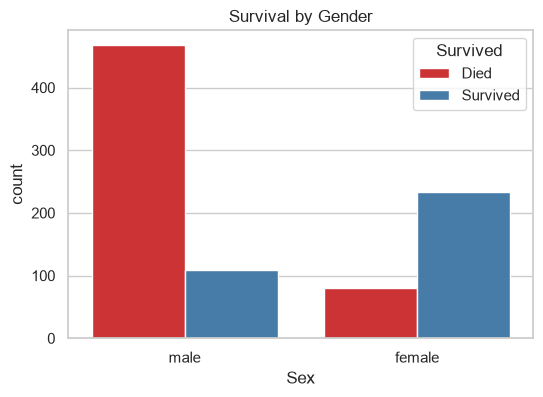

In [105]:
# Plot 4: Survival by gender
fig,ax = plt.subplots(figsize=(6,4))
sns.countplot(data = df , x = "Sex", hue="Survived", palette = "Set1",ax = ax)
ax.set_title("Survival by Gender")
ax.legend(title ="Survived",labels =["Died","Survived"])
plt.show()

Females have drastically more survival rate than male.

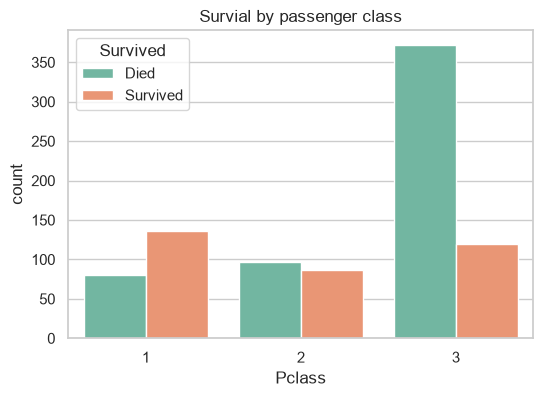

In [129]:
# Plot 5: Survival by Passenger Class
fig,ax = plt.subplots(figsize = (6,4))
sns.countplot(data = df, x = "Pclass",hue = "Survived", palette = "Set2",ax = ax)
ax.set_title("Survial by passenger class")
ax.legend(title = "Survived",labels = ["Died","Survived"])
plt.show()

1st Class passenger has more survival rate compared to 2nd and 3rd, whereas number of passenger died is drastically higher of 3rd Class than 1st and 2nd class.

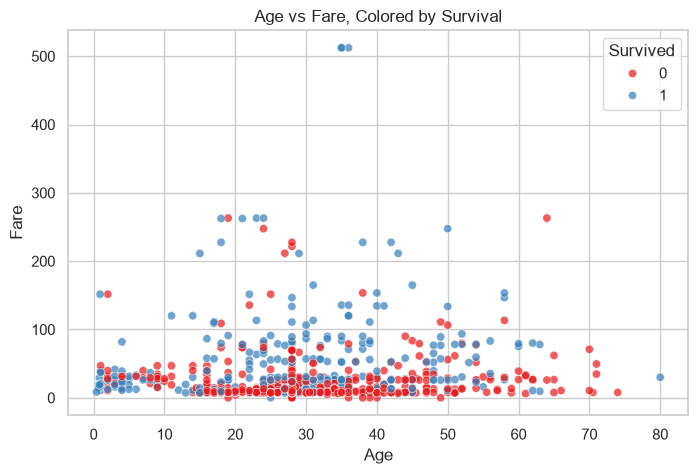

In [131]:
# Plot 6: Age vs Fare Survival
fig,ax = plt.subplots(figsize = (8,5))
sns.scatterplot(data = df, x = "Age", y = "Fare",hue = "Survived", palette= "Set1",alpha = 0.7,ax =ax)
ax.set_title("Age vs Fare, Colored by Survival")
plt.show()

People who paid higher fares (mostly of 1st class) had more chance of surviving regardless of age. 